# 3 · When does the graph pay off? A rule you can check in advance

*Part 3 of the story. Previously: `02_methods_head_to_head.ipynb`.*

**What this notebook answers.** The comparison showed the graph helps under
truncation - but *which* questions flip, and can we know **before building
anything** whether it will help? The logs contain the full ranking for every
candidate, so we can answer both, and the answer turns out to be surprisingly
clean:

> **The graph changes the answer exactly for senses that are (1) buried in the
> default order and (2) reachable through a lexical cue - a word shared between
> the sentence and the sense's neighbourhood. Without a cue the ranking falls
> back to dictionary order; with a cue the sense jumps to rank 1.**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 220)


FULL = al.find_run("skeleton")
payoff = al.payoff_table(FULL)
payoff = payoff[payoff["question_type"] == "sense_disambiguation"].copy()
senses = al.load_senses_table().set_index("sense_id")
payoff["n_senses"] = payoff["gold_sense_id"].map(senses["n_senses_lemma"])
answers_by_cap = {k: al.load_answers(al.find_run(f"cap{k}")) for k in (1, 2, 3)}
print(f"{len(payoff)} sense questions (trick excluded)")
payoff[["question_id", "lemma", "n_senses", "c_position", "d_rank", "score", "signal"]].head(10)

28 sense questions (trick excluded)


,question_id,lemma,n_senses,c_position,d_rank,score,signal
0,q-001,kos,7,2,1,4.0,True
1,q-002,list,3,2,2,0.0,False
2,q-003,greda,7,2,2,0.0,False
3,q-004,obraz,2,2,2,0.0,False
4,q-006,pero,7,1,2,0.0,False
5,q-007,pero,7,2,2,0.0,False
6,q-008,most,9,1,1,0.0,False
7,q-009,most,9,6,6,0.0,False
8,q-010,jabolko,11,3,3,0.0,False
9,q-011,jabolko,11,11,11,0.0,False


**Definitions used below** (all logged, none hand-waved):

- **c_position** - where the gold sense sits in variant C's dictionary order.
- **d_rank** - where the same sense sits in variant D's graph ranking.
- **signal** - did the sentence match ANY part of the gold sense's structured
  neighbourhood (collocations, synonyms, synset literals, hypernym glosses,
  definition tokens)? The graph score is the weighted count of such matches.
- **buried (at budget k)** - c_position > k: the gold would not be shown by C.
- **recovered** - d_rank ≤ k: D does show it.

## The payoff rule: perfect separation at every budget

,budget,buried,"has cue, recovered","has cue, missed","no cue, recovered","no cue, missed"
0,1,21,6,0,0,15
1,2,15,4,0,0,11
2,3,9,3,0,0,6


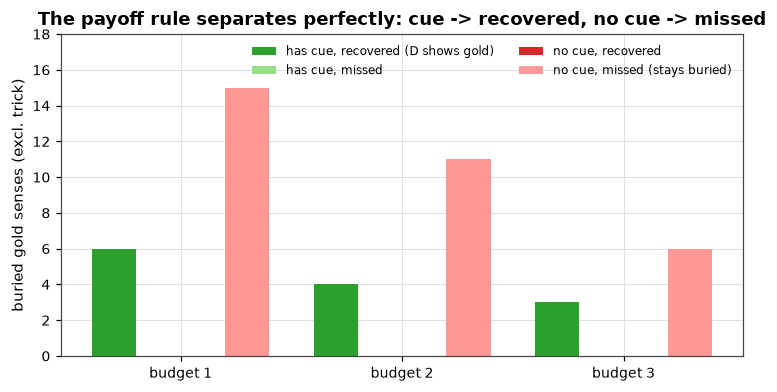

In [2]:
rows = []
for k in (1, 2, 3):
    buried = payoff[payoff["c_position"] > k]
    rows.append({
        "budget": k,
        "buried": len(buried),
        "has cue, recovered": int((buried["signal"] & (buried["d_rank"] <= k)).sum()),
        "has cue, missed": int((buried["signal"] & (buried["d_rank"] > k)).sum()),
        "no cue, recovered": int((~buried["signal"] & (buried["d_rank"] <= k)).sum()),
        "no cue, missed": int((~buried["signal"] & (buried["d_rank"] > k)).sum()),
    })
sep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.0, 3.8))
x = np.arange(len(sep))
w = 0.2
ax.bar(x - 1.5 * w, sep["has cue, recovered"], w, color="#2ca02c", label="has cue, recovered (D shows gold)")
ax.bar(x - 0.5 * w, sep["has cue, missed"], w, color="#98df8a", label="has cue, missed")
ax.bar(x + 0.5 * w, sep["no cue, recovered"], w, color="#d62728", label="no cue, recovered")
ax.bar(x + 1.5 * w, sep["no cue, missed"], w, color="#ff9896", label="no cue, missed (stays buried)")
ax.set_xticks(x, [f"budget {k}" for k in sep["budget"]])
ax.set_ylabel("buried gold senses (excl. trick)")
ax.set_ylim(0, 18)
ax.set_title("The payoff rule separates perfectly: cue -> recovered, no cue -> missed")
ax.legend(fontsize=8, ncol=2)
al.save_figure(fig, "03_payoff_separation")
sep

> **Reading the chart.** The two middle bars - the "crossovers" (a buried sense
> recovered without a cue, or missed despite one) - are **zero at every
> budget**. The rule did not miss a single flip on this question set: every
> buried gold with a cue was recovered; every buried gold without one was not.

## The mechanism: cue -> front, no cue -> dictionary order

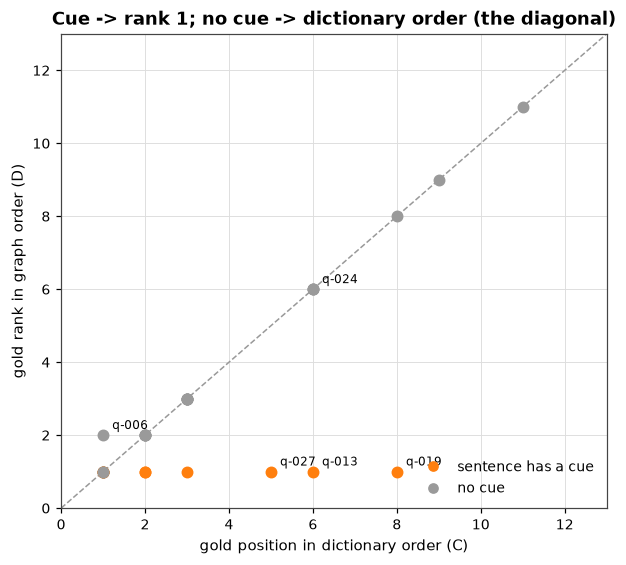

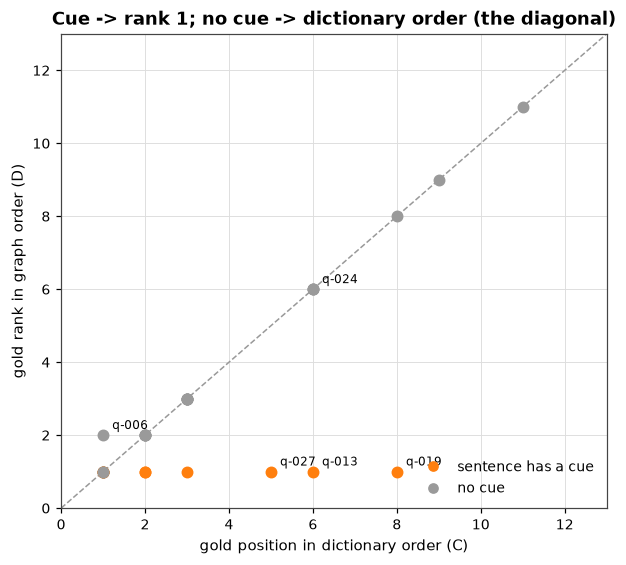

In [3]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(6.4, 5.6))
ax.plot([0, 13], [0, 13], ls="--", color="#999999", lw=1)
for _, r in payoff.iterrows():
    color = al.VARIANT_COLORS["D"] if r["signal"] else "#9a9a9a"
    ax.scatter([r["c_position"]], [r["d_rank"]], s=46, color=color, zorder=3)
for qid in ["q-013", "q-019", "q-027", "q-006", "q-024"]:
    row = payoff[payoff["question_id"] == qid]
    if not row.empty:
        r = row.iloc[0]
        ax.annotate(qid, (r["c_position"], r["d_rank"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
handles = [
    Line2D([], [], marker="o", ls="", color=al.VARIANT_COLORS["D"], label="sentence has a cue"),
    Line2D([], [], marker="o", ls="", color="#9a9a9a", label="no cue"),
]
ax.legend(handles=handles, loc="lower right")
ax.set_xlabel("gold position in dictionary order (C)")
ax.set_ylabel("gold rank in graph order (D)")
ax.set_title("Cue -> rank 1; no cue -> dictionary order (the diagonal)")
ax.set_xlim(0, 13)
ax.set_ylim(0, 13)
al.save_figure(fig, "03_payoff_scatter")
fig

In [4]:
no_cue = payoff[~payoff["signal"]]
same = int((no_cue["c_position"] == no_cue["d_rank"]).sum())
print(f"no-cue questions: {len(no_cue)} | D rank == C position in {same} of them")
no_cue[no_cue["c_position"] != no_cue["d_rank"]][["question_id", "lemma", "c_position", "d_rank", "matched_collocations"]]

no-cue questions: 20 | D rank == C position in 19 of them


,question_id,lemma,c_position,d_rank,matched_collocations
4,q-006,pero,1,2,[]


> **Reading the scatter.** Every cue-bearing gold sense (orange) sits at
> **rank 1** - the ranking is effectively binary: "has a cue -> front". Every
> cue-less sense (grey) stays exactly where the dictionary put it (the
> diagonal), because its graph score is 0 and ties break by dictionary order.
> The two off-diagonal greys are questions where *another* candidate had a cue
> and pushed the gold one slot down (q-006 is the one case where C beats D at
> budget 1, see notebook 2).

> **So the graph is not "understanding" - it is a structured keyword matcher.**
> That is precisely why its behaviour is so predictable, and why it only pays
> off when the sentence actually contains such keywords.

## Where buried senses live: the more polysemous the word, the more the graph matters

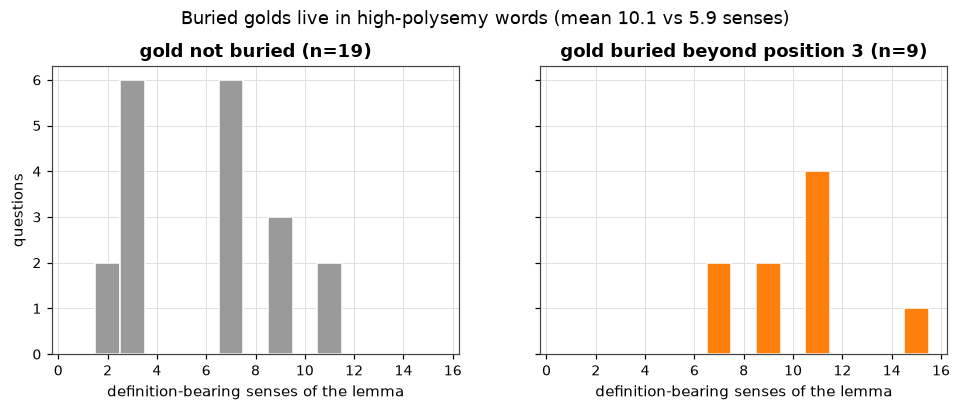

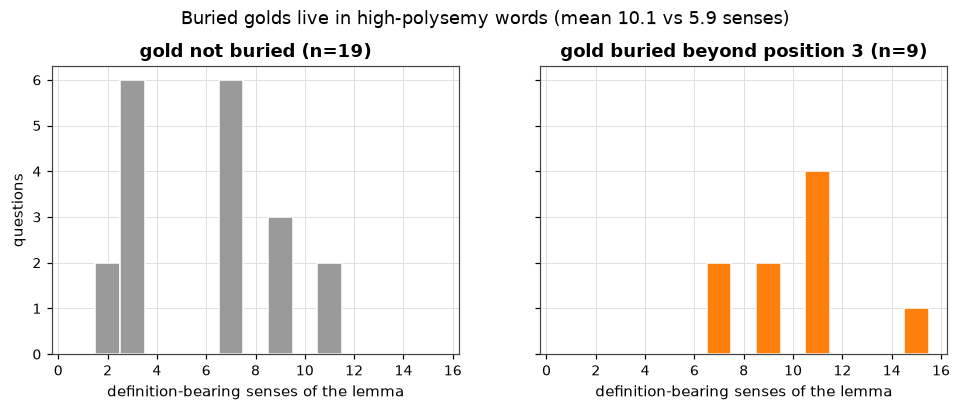

In [5]:
buried_gt3 = payoff[payoff["c_position"] > 3]["n_senses"]
shallow = payoff[payoff["c_position"] <= 3]["n_senses"]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4), sharey=True)
bins = np.arange(1, int(payoff["n_senses"].max()) + 2) - 0.5
axes[0].hist(shallow, bins=bins, color="#9a9a9a", edgecolor="white")
axes[0].set_title(f"gold not buried (n={len(shallow)})")
axes[1].hist(buried_gt3, bins=bins, color=al.VARIANT_COLORS["D"], edgecolor="white")
axes[1].set_title(f"gold buried beyond position 3 (n={len(buried_gt3)})")
for ax in axes:
    ax.set_xlabel("definition-bearing senses of the lemma")
axes[0].set_ylabel("questions")
fig.suptitle(f"Buried golds live in high-polysemy words (mean {buried_gt3.mean():.1f} vs {shallow.mean():.1f} senses)", y=1.03)
al.save_figure(fig, "03_payoff_sense_counts")
fig

> **Reading the chart.** Buried gold senses concentrate in words with many
> senses (mean 10.1 senses vs 5.9 for the rest). This generalises the rule:
> **the value of structured ranking scales with the size of the candidate set
> relative to the budget** - the more senses a word has (and the smaller the
> context), the more often the default order buries the answer.

## Expected gain: measurable before you build anything

,budget,buried / n,P(cue | buried),expected gain (questions),measured gain (questions),expected gain (pp)
0,1,21/28,0.29,6.0,6,21.4
1,2,15/28,0.27,4.0,4,14.3
2,3,9/28,0.33,3.0,3,10.7


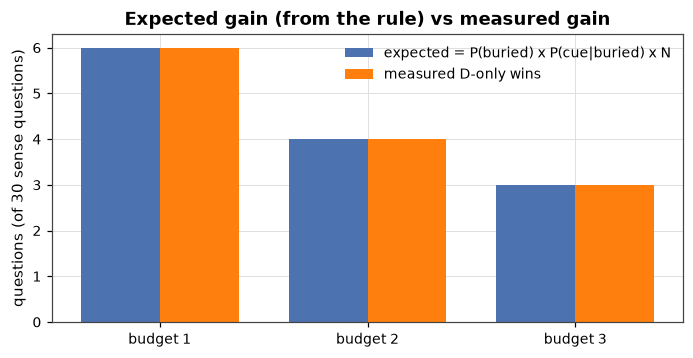

In [6]:
gain_rows = []
for k in (1, 2, 3):
    buried = payoff[payoff["c_position"] > k]
    expected = len(buried) * float(buried["signal"].mean())
    m = al.correctness_matrix(answers_by_cap[k], variants=("C", "D"))
    m = m.loc[m.index.isin(payoff["question_id"])]
    measured = int((m["D"] & ~m["C"]).sum())
    gain_rows.append({
        "budget": k,
        "buried / n": f"{len(buried)}/{len(payoff)}",
        "P(cue | buried)": round(float(buried["signal"].mean()), 2),
        "expected gain (questions)": round(expected, 1),
        "measured gain (questions)": measured,
        "expected gain (pp)": round(100 * expected / len(payoff), 1),
    })
gain = pd.DataFrame(gain_rows)

fig, ax = plt.subplots(figsize=(7.4, 3.4))
x = np.arange(len(gain))
w = 0.38
ax.bar(x - w / 2, gain["expected gain (questions)"], w, color="#4c72b0", label="expected = P(buried) x P(cue|buried) x N")
ax.bar(x + w / 2, gain["measured gain (questions)"], w, color=al.VARIANT_COLORS["D"], label="measured D-only wins")
ax.set_xticks(x, [f"budget {k}" for k in gain["budget"]])
ax.set_ylabel("questions (of 30 sense questions)")
ax.set_title("Expected gain (from the rule) vs measured gain")
ax.legend()
al.save_figure(fig, "03_expected_gain")
gain

> **Reading the chart.** The rule predicts the measured gain exactly: 6, 4 and
> 3 questions at budgets 1, 2 and 3 (+20.0, +13.3 and +10.0 percentage points
> of the 30 sense questions). Both ingredients are measurable **before**
> building or running anything: *how often is the answer buried?*
> (candidate-set size vs context budget) and *how often does the query contain
> a cue?* (token overlap with neighbourhoods).

## The decision checklist: will a knowledge graph pay off?

```
1. Do candidate sets exceed the context budget?
      measure: senses per query vs candidate slots in the prompt
      NO  -> stop; C == D by construction (we measured: full-context run)
      YES -> continue

2. Do queries contain lexical cues from item neighbourhoods?
      measure: token overlap between query and collocations / synonyms /
               definitions / synset words (no gold needed - measure per item)
      NO  -> stop; the ranker has no signal (measured: 0/16 recoveries)
      YES -> continue

3. Estimate the gain:
      expected gain ~= P(buried) x P(cue | buried) x N questions
      here: +10.0 pp (budget 3) ... +20.0 pp (budget 1) of the sense questions

4. Compare the gain with the cost of building + maintaining the graph.
      justified when inventories are large, contexts are tight, and queries
      carry lexical cues (the normal case for dictionary-backed lookups).
```

**The same logic generalises beyond this pilot.** Replace "sense" with any
entity that has (a) a default order (frequency, dictionary position, database
row) and (b) a structured neighbourhood: the rule says *structured ranking pays
exactly when the default order buries the right item and the query carries a
cue*; both conditions are measurable up front, and neither requires an LLM run.

## Validation, honest limits, and the relation extreme

- **Validation**: on this set the rule predicts *every* C-vs-D flip (the
  crossover bars are zero) and the measured gains match the formula exactly.
- **Limit**: the 6 remaining misses are buried senses with **no cue at all**
  (*pero* = spring, *jabolko* = tree, *srce* = drawn shape...). No ordering
  can rescue them - they need **semantic scoring** (comparing meanings, not
  words) or smarter questions. This is the method's boundary, not a bug.
- **The relation pack is the extreme case**: there the cue is a *verified link*
  (the graph edge itself), so the "signal" is always present by construction -
  and indeed relations score 6/6 for C/D/oracle even at budget 1
  (notebook 4). The same rule explains why: perfect cue -> rank 1.

> **Takeaway.** The graph earns its keep in one specific, measurable regime:
> **tight budget + buried answer + a cue in the query**. Outside that regime it
> either cannot matter (everything fits) or cannot help (no cue). That - not a
> single accuracy number - is what "structured knowledge helps" means here.